In [2]:
import numpy as np
from numpy.polynomial.legendre import leggauss as PLG
from scipy.integrate import quad
import math
import scipy.special as sp
import matplotlib.pyplot as plt

In [3]:


## pour des polynomes de dégre differents 
def p1(x):
    return x 
def p2(x):
    return x**2
def p3(x):
    return x**3
def p4(x): 
    return x**4
def p9(x):
    return x**9
def p5(x):
    return x**5
def p6(x):
    return x**6
    
def p10(x):
    return x**10
def p7(x):
    return x**7
def p8(x):
    return x**8

def Gauss_legendre2(f,W,X):

    XX = np.array(X)
    WW = np.array(W)
    return np.sum(WW*f(XX))
    
## on teste pour 2 pooints 

W =[1,1]
X = [-1/np.sqrt(3) , 1/np.sqrt(3)]


#Gauss_legendre2(p4,W,X)


erreur1 = float(quad(p4,-1,1)[0]-Gauss_legendre2(p4,W,X))
#print(f"erreur1 = {erreur1}")
## On remarque que cette formule est vrai pour des polynome de dégré inférieur ou égal à 3 


## Fonction qui approche l'intégrale sur [a,b] de f avec une quadrature de Gauss Legendre à n points
def Gauss_legendre(f,n,a,b):
    # Noeuds et poids sur [-1,1]
    X,W = PLG(n) 
    X,W = np.array(X),np.array(W) 

    # Nouveau noeuds et poids sur [a,b]

    X = (b - a)/2*X + (b + a)/2
    W = (b - a)/2*W

    result = np.sum(W*f(X))

    error = np.abs(quad(f,a,b)[0] - result)

    #print(f" ExactSol = {quad(f,a,b)[0]:.6f}")
    #print(f" Approx_sol = { result:.6f}")
    print(f" Error = {error:.6f}") 

    return 


In [4]:
for k in range(2, 9):
    p = lambda x: x**k 
    Gauss_legendre(p,4,-1,1) 
    #print("  ")
    

    

 Error = 0.000000
 Error = 0.000000
 Error = 0.000000
 Error = 0.000000
 Error = 0.000000
 Error = 0.000000
 Error = 0.011610


In [5]:
X,W = PLG(5)
print(X)

[-0.90617985 -0.53846931  0.          0.53846931  0.90617985]


 Erreur_relative  = 0.012343990885176313:


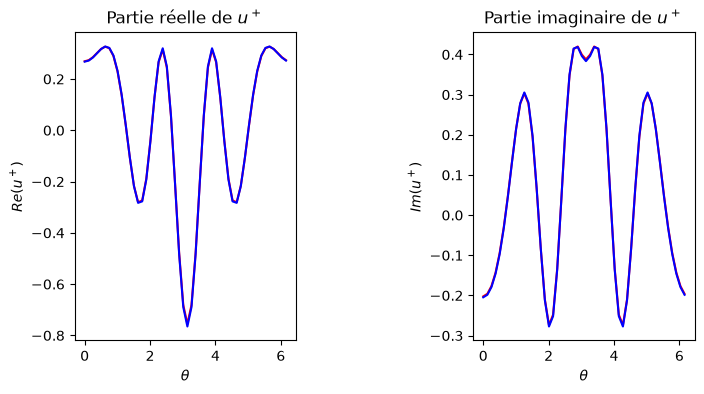

In [20]:
## 3)  On code la representation intégrale sous forme de produit matrice-vecteur

## données du probème 

a = 5.0            # rayon du disque
k = 1.0            # nombre d'onde
Nbre_elmt,Nbre_noeud = 50,50  # nombre de noeud,nombre element
N = 50             # nombre de mode 
m = 50 # nombre de point d'observation
nq = 7  # nombre de points pour la quadrature de Gauss Legendre 

# Point d'observation 
angles = np.linspace(0,2*np.pi,m,endpoint = False)

Xobs = 5*a*np.cos(angles)
Yobs = 5*a*np.sin(angles)
Point_obs = np.transpose(np.vstack((Xobs,Yobs)))
Point_obs2 = Point_obs.copy()


## On récupere les données necessaires du TP0

   


def Geometrie_disque(R,N):

    angles = np.linspace(0,2*np.pi,N,endpoint = False)

    X = R*np.cos(angles) 
    Y = R*np.sin(angles) 
    Num_noeud = np.arange(N)
    
    # Noeuds = [ num_noeuds, xi,yi]
    Noeuds = np.transpose(np.vstack((Num_noeud,X,Y)))

    return Noeuds    

## fonction maillage

def Maillage(Noeuds):

    N = len(Noeuds)

    #Elements =[ [ num_elem, noeud_debut, noeud_fin] ]

    Elements = np.array( [ [ i, i , (i+1)%N  ] for i in range(N)] )
    
    np.set_printoptions(suppress=True)
    
    
    
    Milieux = []
    Longueurs = []
    Normales = []

    for k in range(N):   # pour chaque élement 

        # On recupere les numeros des noeuds qui le constituent

        i_k = Elements[k,1]
        j_k = Elements[k,2] 

        # Noeuds de l'éléments 

        ni = Noeuds[i_k]
        
        nj = Noeuds[j_k]
 
        # coordonnées de chaque noeuds 
        
        xi = ni[1]
        yi = ni[2]

        xj = nj[1]
        yj = nj[2]

        # On calcule lepoint milieu  M_k

        x_M = (xi + xj)/2
        y_M = (yi + yj)/2

        M_k = [ float(x_M),float( y_M) ]
        Milieux.append(M_k)


        # Longueur de l'élément 

        dx = xj - xi
        dy = yj - yi

        lk = float(np.sqrt((dx)**2 + (dy)**2))
        Longueurs.append(lk)

        # Normale exterieure

        n_k = [float(dy/lk),
            float(-dx/lk)]

        Normales.append(n_k)

    Milieux = np.array(Milieux)
    Longueurs = np.array(Longueurs)
    Normales = np.array(Normales)

    return Noeuds,Elements,Milieux,Longueurs,Normales

## Trace normale 

def q(r,theta,k,a,N):

    q = 0 + 0j

    for n in range(-N, N+1):

        q += (-k/2 * (-1j)**n * sp.jv(n,k*a) / sp.hankel1(n,k*a)* (sp.hankel1(n-1,k*r)- sp.hankel1(n+1,k*r)) * np.exp(1j*n*theta))

    return q 


##  LA SOLUTION ANALYTIQUE TRONQUÉ

def U_plus(r,theta,N,k,a):

    u_plus = 0 + 0j

    for n in range (-N,N+1):

        An = - (-1j)**n * sp.jv(n,k*a) / sp.hankel1(n,k*a) 
        u_plus += An * sp.hankel1(n,k*r) * np.exp(1j*n*theta)
    return u_plus


## Champ diffracté

def dU_inc(r,theta,k):
    
    return -1j*k*np.cos(theta)*np.exp(-1j*k*r*np.cos(theta))

def P(r,theta,k,a,N):

    return -q(a,theta,k,a,N) - dU_inc(a,theta,k) 


## Fonction de Green de l'espace libre 2D 


def G(x,y):

    d = np.sqrt((x[0]-y[0])**2 + (x[1] - y[1])**2)
    return 1j/4 * sp.hankel1(0, k*d)


## On commence d'abord par calculer la densité P au milieu des éléments 
## coordonnées polaire des points milieux 

Noeuds,Elements,Milieux,Longueurs,Normales = Maillage(Geometrie_disque(a,Nbre_noeud))


Milieux_en_polaire = np.zeros((Nbre_elmt,2))

Milieux_en_polaire[:,0] = np.sqrt( Milieux[:,0]**2 + Milieux[:,1]**2)  # distance OM pour tous les points Milieux

Milieux_en_polaire[:,1] = np.arctan2(Milieux[:,1],Milieux[:,0]) % (2*np.pi)

PP = P(Milieux_en_polaire[:,0],Milieux_en_polaire[:,1],k,a,N)    ## densité P au points Milieux

## On construit maintenant la matrice A 


zeta,W = PLG(nq)       ## points et poinds de la quadrature de Gauss-Legendre sur [-1,1]

zeta = np.array(zeta)
W = np.array(W)
zetazeta = np.zeros((len(zeta),2))
zetazeta[:,0] = zeta
zetazeta[:,1] = zeta

A = np.zeros((m,Nbre_elmt), dtype = complex)

## DOUBLE BOUCLE /!\
for i in range(m):
    for e in range(Nbre_elmt):
        We = Longueurs[e]/2*W  # We sont les poids sur l'élément e

        # On recupère les Noeuds qui constituent l'élément e
        
        # numéros des Noeuds qui le constituent

        ie = Elements[e,1]
        je = Elements[e,2]

        #noeud de l'élément 

        n1 = Noeuds[ie]
        n2 = Noeuds[je]
        #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
        n1 = n1[1:]
        n2 = n2[1:]

        ## On prend une matrice de taille (nq,2) dont toute le premiere et deuxieme colonne est zeta pour faciment faire le calcul avec numpy
        #zetazeta = np.zeros((len(zeta),2))
        #zetazeta[:,0] = zeta
       # zetazeta[:,1] = zeta
       # print(zetazeta)

        nouv_zeta = (n2 - n1)/2 * zetazeta + (n2 + n1)/2   # points de quadrature sur l'éléments e 
        

        A[i,e] = np.sum(We*np.array([G(Point_obs[i],nouv_zeta[l]) for l in range(nq)]))


U = A@PP



# 4)  Validation : on compare les parties relle et parties immaginaire avec la solution analytique. 

Uref = U_plus(5*a,angles,N,k,a)   # Solution analytique sur le disque de rayon 5a

# Erreur relative 

Erreur = np.max(np.abs(U-Uref))/np.max(np.abs(Uref))

print(f" Erreur_relative  = {Erreur}:")

# On affiche les parties relles et partie imaginaires de la solution analytique et de la solution calculer

fig,ax = plt.subplots(1,2, figsize=(8, 4))
plt.subplots_adjust(hspace=0.4, wspace=0.8)

ax[0].plot(angles,U.real,'r',label = 'partie_relle Solution numerique')
ax[0].plot(angles,Uref.real,'b',label ='partie_relle Solution analytique')
ax[0].set_title(r"Partie réelle de $u^+$")
ax[0].set_xlabel(r"$\theta$")
ax[0].set_ylabel(r"$Re(u^+)$")


ax[1].plot(angles,U.imag,'r',label = 'partie_imag Solution numerique')
ax[1].plot(angles,Uref.imag,'b',label ='partie_imag Solution analytique')
ax[1].set_title(r"Partie imaginaire de $u^+$")
ax[1].set_xlabel(r"$\theta$")
ax[1].set_ylabel(r"$Im(u^+)$")

#plt.legend(loc="lower right")
plt.show()


### TESTS SUR LES DIFFERENTS PARAMETRES

 Erreur_relative  = 0.012343990885176313:
 Erreur_relative  = 0.003094386973976868:
 Erreur_relative  = 0.0007741221932133747:
 Erreur_relative  = 0.00019356340646688741:
 Erreur_relative  = 0.00012388310394796664:
 Erreur_relative  = 3.097161728123015e-05:
l'ordre est: 2.0


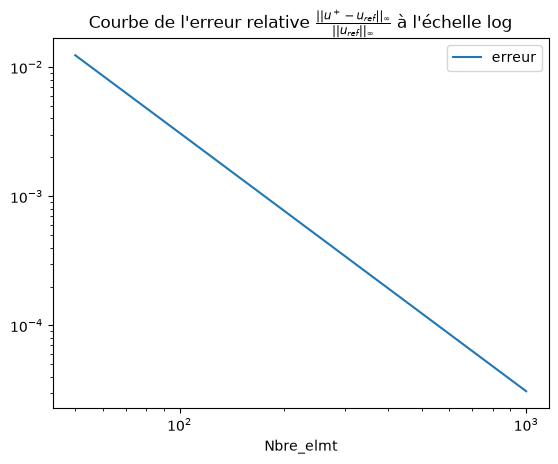

In [6]:
## ON REGARDE L'INFLUENCE DE Nbre_elmt SUR LA SOLUTION

## données du problème fixées 

a = 5.0            # rayon du disque
k = 1.0            # nombre d'onde
N = 50             # nombre de mode 
m = 50 # nombre de point d'observation
nq = 7 # nombre de points pour la quadrature de Gauss Legendre 

# Points d'observation 
angles = np.linspace(0,2*np.pi,m,endpoint = False)

Xobs = 5*a*np.cos(angles)
Yobs = 5*a*np.sin(angles)
Point_obs = np.transpose(np.vstack((Xobs,Yobs)))


# On s'attend à avoir plus de précision sur la solution étant donné qu'il y a plus d'éléments

#vec_Nbre_elmt = [10**i for i in range(1,5)] 
vec_Nbre_elmt = [50,100,200,400,500,1000] 
vec_err = []

for Nbe in vec_Nbre_elmt:
    Noeuds,Elements,Milieux,Longueurs,Normales = Maillage(Geometrie_disque(a,Nbe)) #Nb_noeuds = Nbe aussi


    Milieux_en_polaire = np.zeros((Nbe,2))

    Milieux_en_polaire[:,0] = np.sqrt( Milieux[:,0]**2 + Milieux[:,1]**2)  # distance OM pour tous les points Milieux

    Milieux_en_polaire[:,1] = np.arctan2(Milieux[:,1],Milieux[:,0]) % (2*np.pi)

    PP = P(Milieux_en_polaire[:,0],Milieux_en_polaire[:,1],k,a,N)    ## densité P au points Milieux

    ## On construit maintenant la matrice A 


    zeta,W = PLG(nq)       ## points et poinds de la quadrature de Gauss-Legendre sur [-1,1]

    zeta = np.array(zeta)
    W = np.array(W)

    A = np.zeros((m,Nbe), dtype = complex)

    ## DOUBLE BOUCLE /!\
    for i in range(m):
        for e in range(Nbe):
            We = Longueurs[e]/2*W  # We sont les poids sur l'élément e

            # On recupère les Noeuds qui constituent l'élément e
            
            # numéros des Noeuds qui le constituent

            ie = Elements[e,1]
            je = Elements[e,2]

            #noeud de l'élément 

            n1 = Noeuds[ie]
            n2 = Noeuds[je]
            #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
            n1 = n1[1:]
            n2 = n2[1:]

            ## On prend une matrice de taille (nq,2) dont toute le premiere et deuxieme colonne est zeta pour faciment faire le calcul avec numpy
            zetazeta = np.zeros((len(zeta),2))
            zetazeta[:,0] = zeta
            zetazeta[:,1] = zeta
        # print(zetazeta)

            nouv_zeta = (n2 - n1)/2 * zetazeta + (n2 + n1)/2   # points de quadrature sur l'éléments e 
            

            A[i,e] = np.sum(We*np.array([G(Point_obs[i],nouv_zeta[l]) for l in range(nq)]))


    U = A@PP



    # 4)  Validation : on compare les parties relle et parties immaginaire avec la solution analytique. 

    Uref = U_plus(5*a,angles,N,k,a)   # Solution analytique sur le disque de rayon 5a

    # Erreur relative 

    Erreur = np.max(np.abs(U-Uref))/np.max(np.abs(Uref))
    vec_err.append(Erreur)

    print(f" Erreur_relative  = {Erreur}:")


fig,ax = plt.subplots()

ax.loglog(vec_Nbre_elmt, vec_err, label = 'erreur')
ax.set_title(r"Courbe de l'erreur relative $\frac{||u^+ - u_{ref}||_{\infty}}{||u_{ref}||_{\infty}} $ à l'échelle log")
ax.set_xlabel("Nbre_elmt")
ax.legend()

print(f"l'ordre est: {-np.polyfit(np.log(vec_Nbre_elmt), np.log(vec_err), 1)[0]:.1f}")


 Erreur_relative  = 0.01235227340838621:
 Erreur_relative  = 0.012343990887408455:
 Erreur_relative  = 0.012343990885176313:


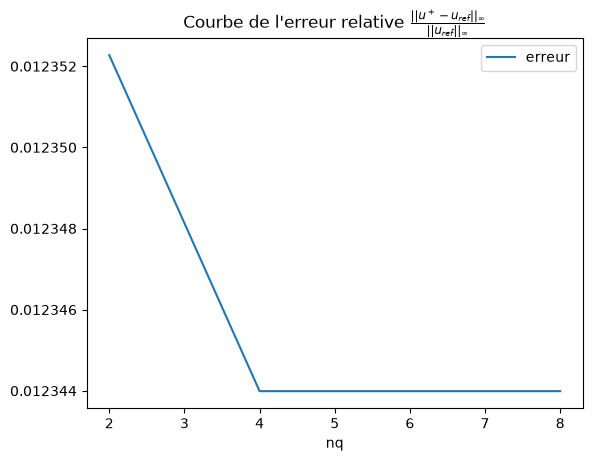

In [7]:
## ON REGARDE L'INFLUENCE DE nq SUR LA SOLUTION

## données du problème fixées 

a = 5.0            # rayon du disque
k = 1.0            # nombre d'onde
Nbre_elmt,Nbre_noeud = 50,50  # nombre de noeud,nombre element
N = 50             # nombre de mode 
m = 50 # nombre de point d'observation

# Points d'observation 
angles = np.linspace(0,2*np.pi,m,endpoint = False)

Xobs = 5*a*np.cos(angles)
Yobs = 5*a*np.sin(angles)
Point_obs = np.transpose(np.vstack((Xobs,Yobs)))


# On s'attend à avoir plus de précision sur la solution étant donné que les intégrales sont plus précises

vec_nq = [2**i for i in range(1, 4)] 
vec_err1 = []

for n in vec_nq:
    Noeuds,Elements,Milieux,Longueurs,Normales = Maillage(Geometrie_disque(a,Nbre_noeud))


    Milieux_en_polaire = np.zeros((Nbre_elmt,2))

    Milieux_en_polaire[:,0] = np.sqrt( Milieux[:,0]**2 + Milieux[:,1]**2)  # distance OM pour tous les points Milieux

    Milieux_en_polaire[:,1] = np.arctan2(Milieux[:,1],Milieux[:,0]) % (2*np.pi)

    PP = P(Milieux_en_polaire[:,0],Milieux_en_polaire[:,1],k,a,N)    ## densité P au points Milieux

    ## On construit maintenant la matrice A 


    zeta,W = PLG(n)       ## points et poinds de la quadrature de Gauss-Legendre sur [-1,1]

    zeta = np.array(zeta)
    W = np.array(W)

    A = np.zeros((m,Nbre_elmt), dtype = complex)

    ## DOUBLE BOUCLE /!\
    for i in range(m):
        for e in range(Nbre_elmt):
            We = Longueurs[e]/2*W  # We sont les poids sur l'élément e

            # On recupère les Noeuds qui constituent l'élément e
            
            # numéros des Noeuds qui le constituent

            ie = Elements[e,1]
            je = Elements[e,2]

            #noeud de l'élément 

            n1 = Noeuds[ie]
            n2 = Noeuds[je]
            #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
            n1 = n1[1:]
            n2 = n2[1:]

            ## On prend une matrice de taille (nq,2) dont toute le premiere et deuxieme colonne est zeta pour faciment faire le calcul avec numpy
            zetazeta = np.zeros((len(zeta),2))
            zetazeta[:,0] = zeta
            zetazeta[:,1] = zeta
        # print(zetazeta)

            nouv_zeta = (n2 - n1)/2 * zetazeta + (n2 + n1)/2   # points de quadrature sur l'éléments e 
            

            A[i,e] = np.sum(We*np.array([G(Point_obs[i],nouv_zeta[l]) for l in range(n)]))


    U = A@PP



    # 4)  Validation : on compare les parties relle et parties immaginaire avec la solution analytique. 

    Uref = U_plus(5*a,angles,N,k,a)   # Solution analytique sur le disque de rayon 5a

    # Erreur relative 

    Erreur = np.max(np.abs(U-Uref))/np.max(np.abs(Uref))
    vec_err1.append(Erreur)

    print(f" Erreur_relative  = {Erreur}:")
    

fig,ax = plt.subplots()

ax.plot(vec_nq, vec_err1, label = 'erreur')
ax.set_title(r"Courbe de l'erreur relative $\frac{||u^+ - u_{ref}||_{\infty}}{||u_{ref}||_{\infty}} $")
ax.set_xlabel("nq")
ax.legend()




<>:97: SyntaxWarning: invalid escape sequence '\G'
<>:97: SyntaxWarning: invalid escape sequence '\G'
/tmp/ipykernel_1162/1138955528.py:97: SyntaxWarning: invalid escape sequence '\G'
  ax.set_xlabel("$||\Gamma - r||$")


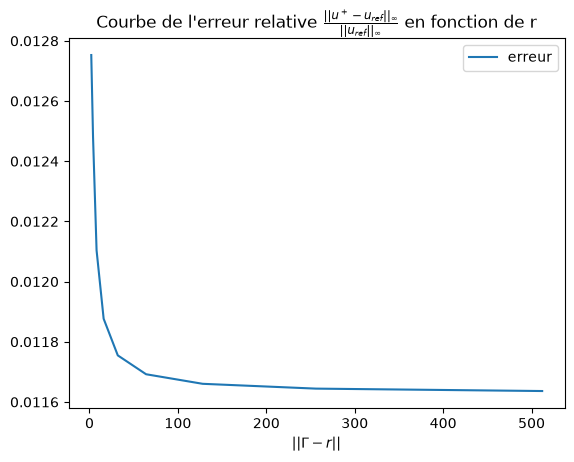

In [8]:
## ON REGARDE L'INFLUENCE DE LA POSITION DU POINT D'OBSERVATION SUR LA SOLUTION

# On s'attend à voir la solution 

## données du problème fixées

a = 5.0            # rayon du disque
k = 1.0            # nombre d'onde
Nbre_elmt,Nbre_noeud = 50,50  # nombre de noeud,nombre element
N = 50             # nombre de mode 
m = 50 # nombre de point d'observation
nq = 7  # nombre de points pour la quadrature de Gauss Legendre 

# Point d'observation, on change la distance à la frontière

vec_r = [2**i for i in range(1, 10)] # on est au minimim à 2r de la frontière
vec_err2 = []

for r in vec_r:
    Xobs = r*a*np.cos(angles)
    Yobs = r*a*np.sin(angles)
    Point_obs = np.transpose(np.vstack((Xobs,Yobs)))


    Noeuds,Elements,Milieux,Longueurs,Normales = Maillage(Geometrie_disque(a,Nbre_noeud))


    Milieux_en_polaire = np.zeros((Nbre_elmt,2))

    Milieux_en_polaire[:,0] = np.sqrt( Milieux[:,0]**2 + Milieux[:,1]**2)  # distance OM pour tous les points Milieux

    Milieux_en_polaire[:,1] = np.arctan2(Milieux[:,1],Milieux[:,0]) % (2*np.pi)

    PP = P(Milieux_en_polaire[:,0],Milieux_en_polaire[:,1],k,a,N)    ## densité P au points Milieux

    ## On construit maintenant la matrice A 


    zeta,W = PLG(nq)       ## points et poinds de la quadrature de Gauss-Legendre sur [-1,1]

    zeta = np.array(zeta)
    W = np.array(W)

    A = np.zeros((m,Nbre_elmt), dtype = complex)

    ## DOUBLE BOUCLE /!\
    for i in range(m):
        for e in range(Nbre_elmt):
            We = Longueurs[e]/2*W  # We sont les poids sur l'élément e

            # On recupère les Noeuds qui constituent l'élément e
            
            # numéros des Noeuds qui le constituent

            ie = Elements[e,1]
            je = Elements[e,2]

            #noeud de l'élément 

            n1 = Noeuds[ie]
            n2 = Noeuds[je]
            #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
            n1 = n1[1:]
            n2 = n2[1:]

            ## On prend une matrice de taille (nq,2) dont toute le premiere et deuxieme colonne est zeta pour faciment faire le calcul avec numpy
            zetazeta = np.zeros((len(zeta),2))
            zetazeta[:,0] = zeta
            zetazeta[:,1] = zeta
        # print(zetazeta)

            nouv_zeta = (n2 - n1)/2 * zetazeta + (n2 + n1)/2   # points de quadrature sur l'éléments e 
            

            A[i,e] = np.sum(We*np.array([G(Point_obs[i],nouv_zeta[l]) for l in range(nq)]))


    U = A@PP



    # 4)  Validation : on compare les parties relle et parties immaginaire avec la solution analytique. 

    Uref = U_plus(r*a,angles,N,k,a)   # Solution analytique sur le disque de rayon 5a

    # Erreur relative 

    Erreur = np.max(np.abs(U-Uref))/np.max(np.abs(Uref))
    vec_err2.append(Erreur)

    #print(f" Erreur_relative  = {Erreur}:")


fig,ax = plt.subplots()
ax.plot(vec_r, vec_err2, label = 'erreur')
ax.set_title(r"Courbe de l'erreur relative $\frac{||u^+ - u_{ref}||_{\infty}}{||u_{ref}||_{\infty}}$ en fonction de r")
ax.set_xlabel("$||\Gamma - r||$")
ax.legend()


In [ ]:
######################## Test avec l'interpolation de degré 1 (Pas terminé) #######################################

Noeuds,Elements,Milieux,Longueurs,Normales = Maillage(Geometrie_disque(a,Nbre_noeud))


"""Milieux_en_polaire = np.zeros((Nbre_elmt,2))

Milieux_en_polaire[:,0] = np.sqrt( Milieux[:,0]**2 + Milieux[:,1]**2)  # distance OM pour tous les points Milieux

Milieux_en_polaire[:,1] = np.arctan2(Milieux[:,1],Milieux[:,0]) % (2*np.pi)"""

coord1 = np.zeros((Nbre_elmt, 2))
coord1[:,0] = np.sqrt(Noeuds[:-1, 1]**2 + Noeuds[:-1, 2]**2 ) # distance OP1 pour le premier extremité
coord1[:,1] = np.arctan2(Noeuds[:-1,1],Noeuds[:-1,2]) % (2*np.pi)

PP1 = P(Noeuds[:-1,1],Noeuds[:-1,2],k,a,N)    ## densité P au points Milieux

coord2 = np.zeros((Nbre_elmt, 2))
coord2[:,0] = np.sqrt(Noeuds[1:, 1]**2 + Noeuds[1:, 2]**2 ) # distance OP1 pour le premier extremité
coord2[:,1] = np.arctan2(Noeuds[1:,1],Noeuds[1:,2]) % (2*np.pi)

PP2 = P(Noeuds[1:,1],Noeuds[1:,2],k,a,N) 

#Il faut récupérer les fonctions de formes parce qu'on peut pas les sortir de l'intégrale


## On construit maintenant la matrice A 


zeta,W = PLG(nq)       ## points et poinds de la quadrature de Gauss-Legendre sur [-1,1]

zeta = np.array(zeta)
W = np.array(W)

A = np.zeros((m,Nbre_elmt), dtype = complex)

## DOUBLE BOUCLE /!\
for i in range(m):
    for e in range(Nbre_elmt):
        We = Longueurs[e]/2*W  # We sont les poids sur l'élément e

        # On recupère les Noeuds qui constituent l'élément e
        
        # numéros des Noeuds qui le constituent

        ie = Elements[e,1]
        je = Elements[e,2]

        #noeud de l'élément 

        n1 = Noeuds[ie]
        n2 = Noeuds[je]
        #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
        n1 = n1[1:]
        n2 = n2[1:]

        ## On prend une matrice de taille (nq,2) dont toute le premiere et deuxieme colonne est zeta pour faciment faire le calcul avec numpy
        zetazeta = np.zeros((len(zeta),2))
        zetazeta[:,0] = zeta
        zetazeta[:,1] = zeta
       # print(zetazeta)

        nouv_zeta = (n2 - n1)/2 * zetazeta + (n2 + n1)/2   # points de quadrature sur l'éléments e 
        

        A[i,e] = np.sum(We*np.array([G(Point_obs[i],nouv_zeta[l]) for l in range(nq)]))


U = A@PP



# 4)  Validation : on compare les parties relle et parties immaginaire avec la solution analytique. 

Uref = U_plus(5*a,angles,N,k,a)   # Solution analytique sur le disque de rayon 5a

# Erreur relative 

Erreur = np.max(np.abs(U-Uref))/np.max(np.abs(Uref))

print(f" Erreur_relative  = {Erreur}:")

# On affiche les parties relles et partie imaginaires de la solution analytique et de la solution calculer

fig,ax = plt.subplots(1,2)
plt.subplots_adjust(hspace=0.4, wspace=0.8)

ax[0].plot(angles,U.real,'r',label = 'partie_relle Solution numerique')
ax[0].plot(angles,Uref.real,'b',label ='partie_relle Solution analytique')
ax[0].set_title(r"Partie réelle de $u^+$")
ax[0].set_xlabel(r"$\theta$")
ax[0].set_ylabel(r"$Re(u^+)$")


ax[1].plot(angles,U.imag,'r',label = 'partie_imag Solution numerique')
ax[1].plot(angles,Uref.imag,'b',label ='partie_imag Solution analytique')
ax[1].set_title(r"Partie imaginaire de $u^+$")
ax[1].set_xlabel(r"$\theta$")
ax[1].set_ylabel(r"$Im(u^+)$")

plt.legend(loc="lower right")
plt.show()

ValueError: could not broadcast input array from shape (49,) into shape (50,)

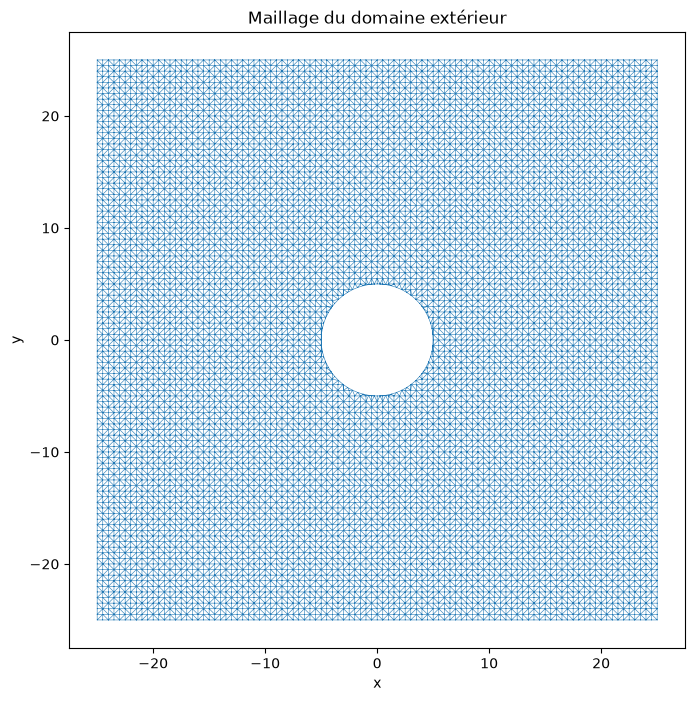

In [9]:
## Maillage du domaine exterieur de la fonctiere pour evaluer le champ diffracté avec VIZIR 4 qwsur un domaine 2D pas juste sur le disque de rayon 5a
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay


def Maillage_exterieur_disque(a, R_ext, h):

    # -------------------------------------------------------
    # 1. Grille de points dans le carré extérieur
    # -------------------------------------------------------

    x = np.arange(-R_ext, R_ext + h, h)
    y = np.arange(-R_ext, R_ext + h, h)

    X, Y = np.meshgrid(x, y)

    Points = np.column_stack((X.ravel(), Y.ravel()))


    # -------------------------------------------------------
    # 2. On supprime les points situés à l'intérieur
    #    de l'obstacle r < a
    # -------------------------------------------------------

    r = np.sqrt(Points[:, 0]**2 + Points[:, 1]**2)

    Points = Points[r >= a]


    # -------------------------------------------------------
    # 3. Ajout de points exactement sur Gamma
    # -------------------------------------------------------

    N_gamma = max(30, int(2*np.pi*a/h))

    theta = np.linspace(0, 2*np.pi, N_gamma, endpoint=False)

    Gamma = np.column_stack((
        a*np.cos(theta),
        a*np.sin(theta)
    ))

    Points = np.vstack((Points, Gamma))


    # -------------------------------------------------------
    # 4. Triangulation de Delaunay
    # -------------------------------------------------------

    triangulation = Delaunay(Points)

    Triangles = triangulation.simplices


    # -------------------------------------------------------
    # 5. Suppression des triangles qui tombent
    #    dans le disque
    # -------------------------------------------------------

    centres = Points[Triangles].mean(axis=1)

    r_centres = np.sqrt(
        centres[:, 0]**2 +
        centres[:, 1]**2
    )

    Triangles = Triangles[r_centres >= a]


    return Points, Triangles

a = 5.0

R_ext = 5*a

h = 0.5

Points_ext, Triangles_ext = Maillage_exterieur_disque(
    a,
    R_ext,
    h
)

plt.figure(figsize=(8, 8))

plt.triplot(
    Points_ext[:, 0],
    Points_ext[:, 1],
    Triangles_ext,
    linewidth=0.4
)

plt.gca().set_aspect("equal")

plt.xlabel("x")
plt.ylabel("y")

plt.title("Maillage du domaine extérieur")

plt.show()


In [ ]:
Point_obs = Points_ext

m = len(Point_obs)
A = np.zeros((m, Nbre_elmt), dtype=complex)
for i in range(m):
    for e in range(Nbre_elmt):
        We = Longueurs[e]/2*W  # We sont les poids sur l'élément e

        # On recupère les Noeuds qui constituent l'élément e
        
        # numéros des Noeuds qui le constituent

        ie = Elements[e,1]
        je = Elements[e,2]

        #noeud de l'élément 

        n1 = Noeuds[ie]
        n2 = Noeuds[je]
        #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
        n1 = n1[1:]
        n2 = n2[1:]

        ## On prend une matrice de taille (nq,2) dont toute le premiere et deuxieme colonne est zeta pour faciment faire le calcul avec numpy
        zetazeta = np.zeros((len(zeta),2))
        zetazeta[:,0] = zeta
        zetazeta[:,1] = zeta
       # print(zetazeta)

        nouv_zeta = (n2 - n1)/2 * zetazeta + (n2 + n1)/2   # points de quadrature sur l'éléments e 
        

        A[i,e] = np.sum(We*np.array([G(Point_obs[i],nouv_zeta[l]) for l in range(nq)]))




u_num = A @ PP
u_re = np.real(u_num)
u_im = np.imag(u_num)

x = Point_obs[:, 0]
y = Point_obs[:, 1]

r = np.sqrt(x**2 + y**2)
theta = np.arctan2(y, x)

u_ref = U_plus(r, theta, N, k, a) 

Erreur_relative = (
    np.max(np.abs(u_num - u_ref))
    / np.max(np.abs(u_ref))
)

print("Erreur relative =", Erreur_relative)



Erreur relative = 0.02999013211767129


In [16]:
## creation des fichier pour la visualisation avec VIZIR 4

import numpy as np


def export_vizir_mesh(filename, Points, Triangles):
    """
    Ecrit un maillage triangulaire 2D au format .mesh
    compatible ViZiR / Medit.
    """

    with open(filename, "w") as f:

        f.write("MeshVersionFormatted 2\n\n")
        f.write("Dimension 2\n\n")

        # -------------------------
        # Sommets
        # -------------------------
        f.write("Vertices\n")
        f.write(f"{len(Points)}\n")

        for x, y in Points:
            # x y reference
            f.write(f"{x:.15e} {y:.15e} 0\n")

        f.write("\n")

        # -------------------------
        # Triangles
        # -------------------------
        f.write("Triangles\n")
        f.write(f"{len(Triangles)}\n")

        for triangle in Triangles:

            i, j, k = triangle

            # Python : indices 0,1,2,...
            # ViZiR  : indices 1,2,3,...
            f.write(f"{i+1} {j+1} {k+1} 1\n")

        f.write("\nEnd\n")


def export_vizir_sol(filename, u_re, u_im):
    """
    Ecrit Re(u+) et Im(u+) aux sommets
    dans un fichier .sol.
    """

    if len(u_re) != len(u_im):
        raise ValueError(
            "u_re et u_im doivent avoir la même taille."
        )

    with open(filename, "w") as f:

        f.write("MeshVersionFormatted 2\n\n")
        f.write("Dimension 2\n\n")

        f.write("SolAtVertices\n")
        f.write(f"{len(u_re)}\n")

        # Nombre de champs
        f.write("2\n")

        # Type 1 = scalaire
        # deux champs scalaires :
        # Re(u+) et Im(u+)
        f.write("1 1\n")

        for re, im in zip(u_re, u_im):
            f.write(f"{re:.15e} {im:.15e}\n")

        f.write("\nEnd\n")

export_vizir_mesh(
    "champ_u.mesh",
    Points_ext,
    Triangles_ext
)

export_vizir_sol(
    "champ_u.sol",
    u_re,
    u_im
)

print("Fichiers ViZiR créés.")

Fichiers ViZiR créés.


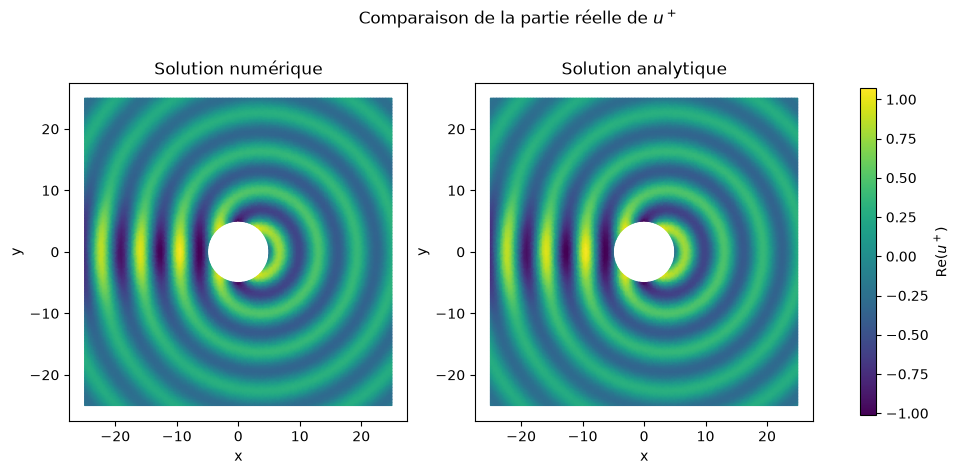

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Parties réelle et imaginaire
u_num_re = np.real(u_num)
u_num_im = np.imag(u_num)

u_ref_re = np.real(u_ref)
u_ref_im = np.imag(u_ref)


# ============================================================
# 1. PARTIES REELLES
# ============================================================

# Même échelle de couleurs pour les deux figures
vmin_re = min(u_num_re.min(), u_ref_re.min())
vmax_re = max(u_num_re.max(), u_ref_re.max())

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

im1 = ax[0].tripcolor(
    Points_ext[:, 0],
    Points_ext[:, 1],
    Triangles_ext,
    u_num_re,
    shading="gouraud",
    vmin=vmin_re,
    vmax=vmax_re
)

ax[0].set_title("Solution numérique")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].set_aspect("equal")


im2 = ax[1].tripcolor(
    Points_ext[:, 0],
    Points_ext[:, 1],
    Triangles_ext,
    u_ref_re,
    shading="gouraud",
    vmin=vmin_re,
    vmax=vmax_re
)

ax[1].set_title("Solution analytique")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_aspect("equal")

# Une seule barre de couleur commune
fig.colorbar(
    im2,
    ax=ax,
    label=r"$\mathrm{Re}(u^+)$",
    shrink=0.85
)

fig.suptitle(r"Comparaison de la partie réelle de $u^+$")

plt.show()

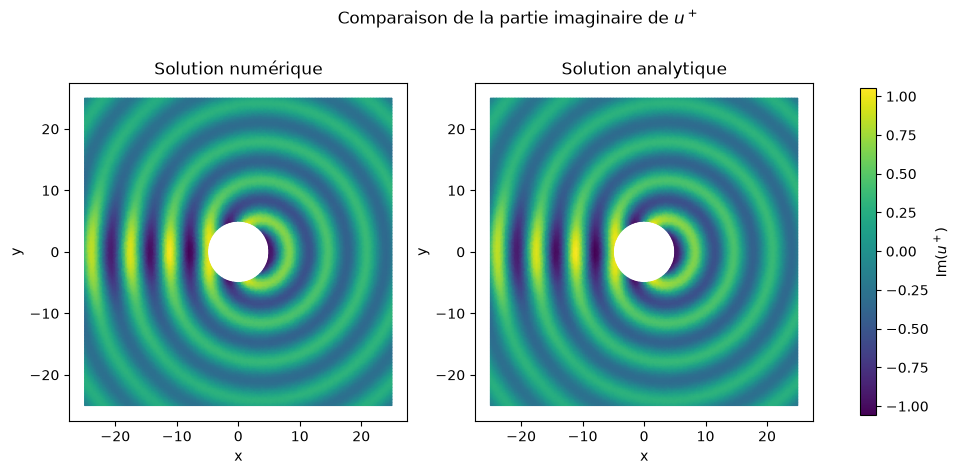

In [19]:
# ============================================================
# 2. PARTIES IMAGINAIRES
# ============================================================

vmin_im = min(u_num_im.min(), u_ref_im.min())
vmax_im = max(u_num_im.max(), u_ref_im.max())

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

im1 = ax[0].tripcolor(
    Points_ext[:, 0],
    Points_ext[:, 1],
    Triangles_ext,
    u_num_im,
    shading="gouraud",
    vmin=vmin_im,
    vmax=vmax_im
)

ax[0].set_title("Solution numérique")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].set_aspect("equal")


im2 = ax[1].tripcolor(
    Points_ext[:, 0],
    Points_ext[:, 1],
    Triangles_ext,
    u_ref_im,
    shading="gouraud",
    vmin=vmin_im,
    vmax=vmax_im
)

ax[1].set_title("Solution analytique")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_aspect("equal")

fig.colorbar(
    im2,
    ax=ax,
    label=r"$\mathrm{Im}(u^+)$",
    shrink=0.85
)

fig.suptitle(r"Comparaison de la partie imaginaire de $u^+$")

plt.show()

 Erreur_relative  = 0.0196734458297127:


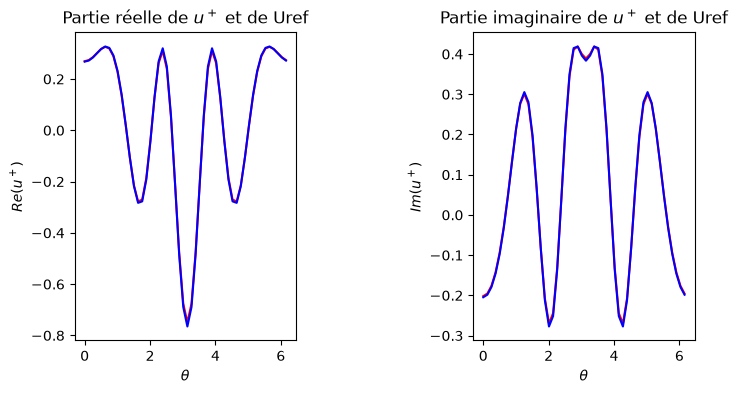

In [21]:
## Partie 5 ) Pur aller plus loin,: On utilise une interpolation lieneaire par élément 

# On construit une nouvelle fonction G2 qui prendre y comme vecteur  pour nous facilité le travail

erreur_approx_lineaire = []
nombre_elt = [50,100,200,400,500]

def G2(x,y):

    result = []
    for i in range (len(y)):
        yy = y[i]
        result.append(G(x,yy))
    return result

    



# calcul dans un premier temps la densité P au noeuds des éléments 

# on recupere nos Noeuds en polaire 

Noeuds,Elements,Milieux,Longueurs,Normales = Maillage(Geometrie_disque(a,Nbre_noeud))

Nouv_Nouv_zeta  = []

Nouv_PP =[]
WWe = []


for e in range(Nbre_elmt):
    WWe.append(Longueurs[e]/4*W)  # We sont les poids sur l'élément e
    

    # On recupère les Noeuds qui constituent l'élément e
    
    # numéros des Noeuds qui le constituent

    ie = Elements[e,1]
    je = Elements[e,2]

    #noeud de l'élément 

    n1 = Noeuds[ie]
    n2 = Noeuds[je]
    #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
    n1 = n1[1:]
    #angles de ce noeuds 
    theta_ae = np.arctan2(n1[1],n1[0])
    n2 = n2[1:]
    theta_be = np.arctan2(n2[1],n2[0])

   # be_plus_ae.append( n2 + n1)
   # be_moins_ae.append(n2 - n1)

    Nouv_PP.append(P(a,theta_ae,k,a,N)*(1-zeta) + P(a,theta_be,k,a,N)*(1 + zeta))

    Nouv_Nouv_zeta.append(0.5*(n2 + n1) + 0.5*zetazeta*(n2-n1))
    
Nouv_PP = np.array(Nouv_PP)
Nouv_Nouv_zeta = np.array(Nouv_Nouv_zeta)
WWe = np.array(WWe)


# On construit la solution U+
UU = np.zeros(len(Point_obs2), dtype= complex)
for i in range( len(Point_obs2)):
    UU[i] =  np.sum([np.sum(WWe[e]*G2(Point_obs2[i],Nouv_Nouv_zeta[e])*(Nouv_PP[e])) for e in range(Nbre_elmt)])





Erreur2 = np.max(np.abs(UU-Uref))/np.max(np.abs(Uref))

print(f" Erreur_relative  = {Erreur2}:")

# On affiche les parties relles et partie imaginaires de la solution analytique et de la solution numérique

fig,ax = plt.subplots(1,2, figsize=(8, 4))
plt.subplots_adjust(hspace=0.4, wspace=0.8)

ax[0].plot(angles,UU.real,'r',label = 'partie_relle Solution numerique')
ax[0].plot(angles,Uref.real,'b',label ='partie_relle Solution analytique')
ax[0].set_title(r"Partie réelle de $u^+$ et de Uref")
ax[0].set_xlabel(r"$\theta$")
ax[0].set_ylabel(r"$Re(u^+)$")



ax[1].plot(angles,UU.imag,'r',label = 'partie_imag Solution numerique')
ax[1].plot(angles,Uref.imag,'b',label ='partie_imag Solution analytique')
ax[1].set_title(r"Partie imaginaire de $u^+$ et de Uref")
ax[1].set_xlabel(r"$\theta$")
ax[1].set_ylabel(r"$Im(u^+)$")


#plt.legend(loc="lower right")
plt.show()






In [43]:
def p (x,y):
    return x +y

x = 2 
y = np.arange(0,5,1)
print(p(x,y))

[2 3 4 5 6]


In [22]:
## Partie 5 ) Pur aller plus loin,: On utilise une interpolation lieneaire par élément 

# On construit une nouvelle fonction G2 qui prendre y comme vecteur  pour nous facilité le travail

erreur_approx_lineaire = []
nombre_elt = [50,100,200,400,500,1000]
for Nbre_elmt in nombre_elt:

    def G2(x,y):

        result = []
        for i in range (len(y)):
            yy = y[i]
            result.append(G(x,yy))
        return result

        



    # calcul dans un premier temps la densité P au noeuds des éléments 

    # on recupere nos Noeuds en polaire 

    Noeuds,Elements,Milieux,Longueurs,Normales = Maillage(Geometrie_disque(a,Nbre_elmt))

    Nouv_Nouv_zeta  = []

    Nouv_PP =[]
    WWe = []


    for e in range(Nbre_elmt):
        WWe.append(Longueurs[e]/4*W)  # We sont les poids sur l'élément e
        

        # On recupère les Noeuds qui constituent l'élément e
        
        # numéros des Noeuds qui le constituent

        ie = Elements[e,1]
        je = Elements[e,2]

        #noeud de l'élément 

        n1 = Noeuds[ie]
        n2 = Noeuds[je]
        #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
        n1 = n1[1:]
        #angles de ce noeuds 
        theta_ae = np.arctan2(n1[1],n1[0])
        n2 = n2[1:]
        theta_be = np.arctan2(n2[1],n2[0])

    # be_plus_ae.append( n2 + n1)
    # be_moins_ae.append(n2 - n1)

        Nouv_PP.append(P(a,theta_ae,k,a,N)*(1-zeta) + P(a,theta_be,k,a,N)*(1 + zeta))

        Nouv_Nouv_zeta.append(0.5*(n2 + n1) + 0.5*zetazeta*(n2-n1))
        
    Nouv_PP = np.array(Nouv_PP)
    Nouv_Nouv_zeta = np.array(Nouv_Nouv_zeta)
    WWe = np.array(WWe)


    # On construit la solution U+
    UU = np.zeros(len(Point_obs2), dtype= complex)
    for i in range( len(Point_obs2)):
        UU[i] =  np.sum([np.sum(WWe[e]*G2(Point_obs2[i],Nouv_Nouv_zeta[e])*(Nouv_PP[e])) for e in range(Nbre_elmt)])





    Erreur2 = np.max(np.abs(UU-Uref))/np.max(np.abs(Uref))
    erreur_approx_lineaire.append(Erreur2)




print(erreur_approx_lineaire)

[np.float64(0.0196734458297127), np.float64(0.004963585122092223), np.float64(0.0012437467342999889), np.float64(0.000311115214238665), np.float64(0.0001991274547699742), np.float64(4.978643678695017e-05)]
